<a href="https://colab.research.google.com/github/akhdanfaiq/JOSA-Juice-CO./blob/main/Modul_3_KKA_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LATIHAN 1

In [ ]:
import pandas as pd
df = pd.read_csv('penjualan_nusantaramart.csv')
print(df.head()) # lihat 5 baris pertama
print(df.info()) # tipe data & jumlah data kosong
print(df.describe()) # ringkasan statistik
# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

      tanggal    kategori_produk  jumlah    total  rating_pelanggan
0  2024-04-12  Makanan & Minuman       6   600000          3.346589
1  2024-06-28         Elektronik       7  1750000          3.312874
2  2024-04-02  Makanan & Minuman       4   200000          3.500486
3  2024-01-15    Kebutuhan Rumah       7   700000          4.098453
4  2024-04-16            Fashion       8   400000          4.429192
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tanggal           100 non-null    object 
 1   kategori_produk   100 non-null    object 
 2   jumlah            100 non-null    int64  
 3   total             100 non-null    int64  
 4   rating_pelanggan  100 non-null    float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ KB
None
           jumlah         total  rating_pelanggan
count  100.000000  1.000000e+02        100.

1. kategori produk apa yang memiliki rata-rata nilai transaksi (total) tertinggi?

Jawaban: kategori Elektronik memiliki rata-rata nilai transaksi tertinggi, yaitu sebesar Rp363.541,67.

2. apakah ada kolom yang memiliki data kosong (missing value)?

Jawaban: tidak ada kolom yang memiliki data kosong (missing value). Hal ini dibuktikan dari output df.info() yang menunjukkan seluruh kolom memiliki Non-Null Count sebanyak 220, sama dengan jumlah seluruh baris data.

3. bandingkan nilai mean dan median kolom total secara keseluruhan. apa yang bisa kamu simpulkan?

Jawaban:
- Mean (rata-rata): Rp238.486,36
- Median (nilai tengah): Rp125.000

Nilai mean lebih besar daripada median. Hal ini menunjukkan bahwa sebaran data cenderung miring ke kanan (right-skewed). Artinya, terdapat beberapa transaksi dengan nilai yang jauh lebih besar sehingga menaikkan nilai rata-rata.

LATIHAN 2

/tmp/ipykernel_464/1140824476.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


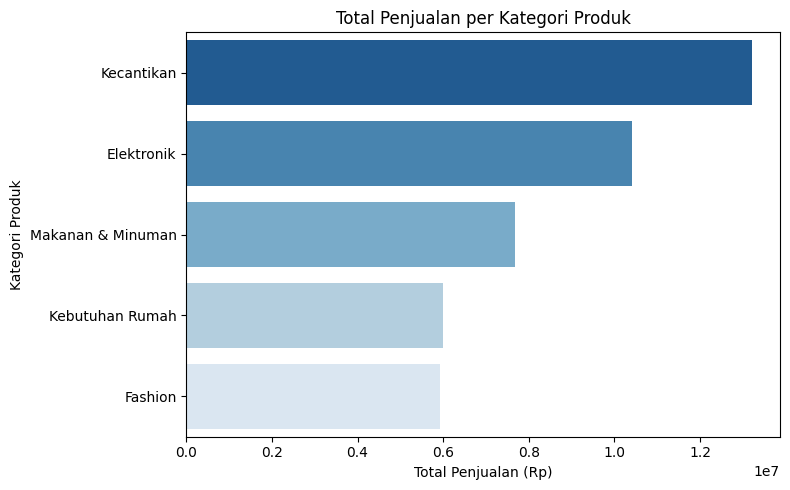

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

1. Kategori apa yang menyumbang penjualan tertinggi dan terendah?
Jawaban:

- Tertinggi: Fashion, dengan total penjualan sekitar Rp17,7 juta.
- Terendah: Makanan & Minuman, dengan total penjualan sekitar Rp2,9 juta.

2. Rekomendasi bisnis untuk manajer NusantaraMart

Jawaban: Manajer sebaiknya mempertahankan penjualan Fashion dan Elektronik serta meningkatkan penjualan Makanan & Minuman melalui promosi dan diskon agar minat beli pelanggan meningkat.

LATIHAN 3

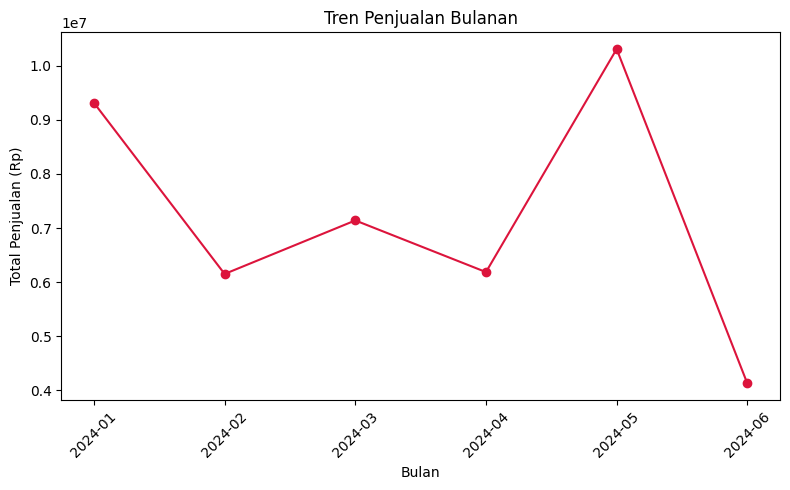

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()
plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

1. Bulan apa yang memiliki penjualan tertinggi? Menurutmu, apa kemungkinan penyebabnya?

Bulan Mei memiliki penjualan tertinggi dengan total omzet sebesar Rp13.585.000. Kemungkinan penyebabnya adalah meningkatnya minat pembeli terhadap produk yang dijual, adanya kebutuhan tertentu, serta beberapa produk yang dibeli dalam jumlah banyak.

2. Apakah tren penjualan cenderung naik, turun, atau fluktuatif? Jelaskan.

Tren penjualan cenderung fluktuatif (naik dan turun). Pada Januari hingga Mei, penjualan secara umum mengalami peningkatan, tetapi pada Juni mengalami penurunan cukup besar. Hal ini menunjukkan bahwa jumlah penjualan setiap bulan belum stabil.

LATIHAN 4

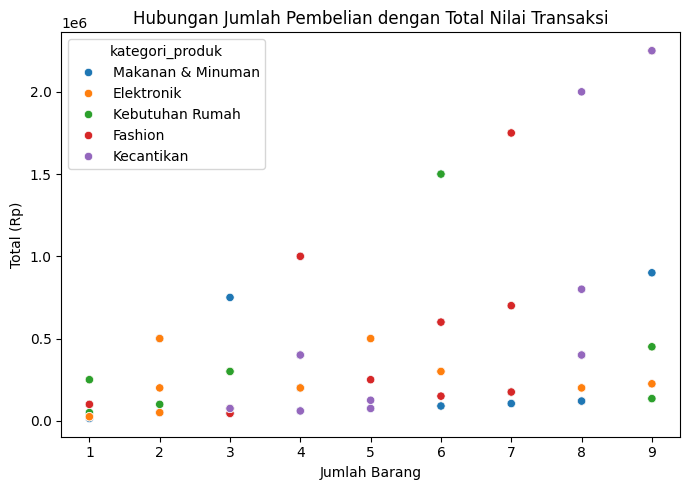

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()


1. Apakah terlihat pola hubungan antara jumlah barang dan total nilai transaksi?

Terlihat hubungan positif. Artinya, semakin banyak jumlah barang yang dibeli, biasanya semakin besar total nilai transaksinya. Hal ini karena total transaksi dipengaruhi oleh jumlah barang dan harga satuan.

2. Apakah ada titik data yang terlihat jauh dari pola umum (outlier)? Sebutkan kategorinya jika terlihat dari warna.

Ada beberapa data yang terlihat menonjol dibandingkan transaksi lainnya, yaitu:
- Elektronik: pembelian 40 Earphone Bluetooth dengan total Rp3.400.000.
- Olahraga: pembelian 40 Botol Minum 1L dengan total Rp1.600.000.
- Kesehatan: pembelian 25 Termometer Digital dengan total Rp1.500.000.
- Elektronik: pembelian 25 Speaker Mini dengan total Rp2.375.000

LATIHAN 5

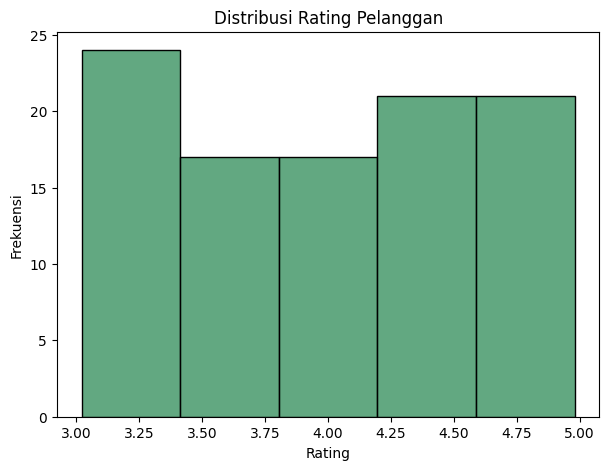

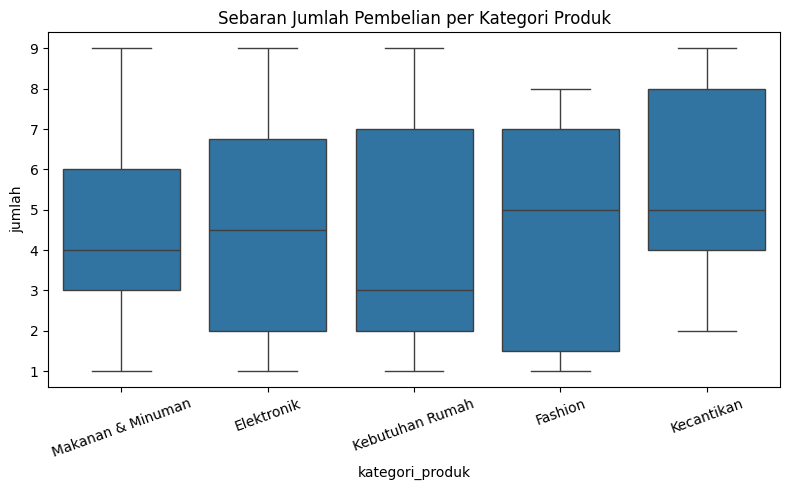

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()
# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


1. Bagaimana bentuk distribusi rating pelanggan?

Rating pelanggan cenderung tinggi. Sebagian besar pelanggan memberikan rating 4 dan 5. Hal ini menunjukkan bahwa kebanyakan pelanggan merasa puas terhadap produk atau pelayanan yang diberikan.

2. Kategori produk mana yang memiliki titik-titik di luar kotak boxplot (outlier)? Apa kemungkinan penyebabnya?

Kategori yang memiliki kemungkinan outlier pada nilai transaksi adalah:
- Elektronik: terdapat transaksi dengan nilai yang jauh lebih besar dari transaksi lainnya.
- Kesehatan: terdapat beberapa transaksi dengan jumlah pembelian besar.
- Makanan & Minuman: terdapat transaksi dengan nilai yang cukup tinggi.
- Olahraga: terdapat transaksi dengan jumlah barang yang banyak.
Kategori Fashion tidak menunjukkan outlier yang menonjol.

Kemungkinan penyebabnya adalah adanya pembelian dalam jumlah besar, misalnya oleh reseller atau pelanggan yang membeli barang untuk dijual kembali.

LATIHAN 6

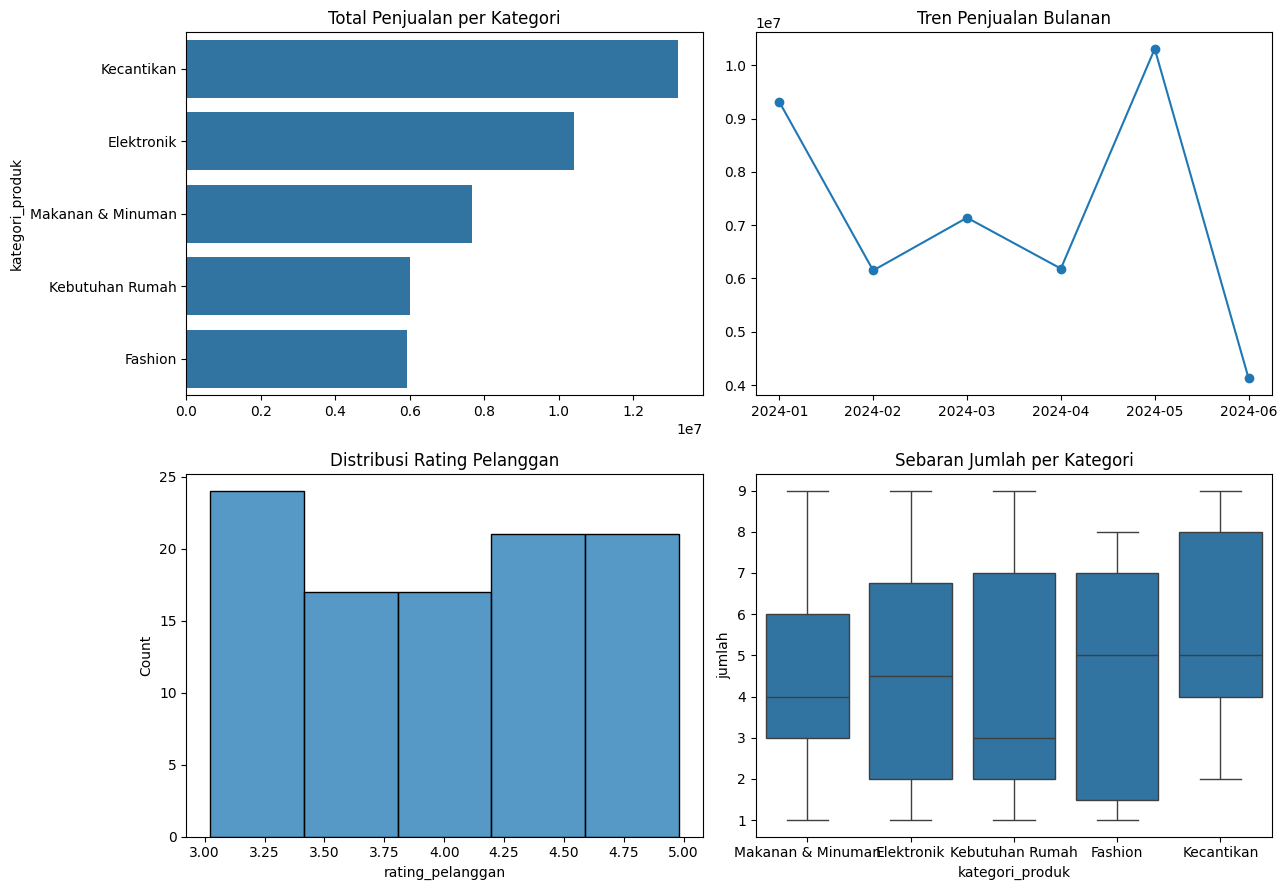

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))
sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')
axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')
sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Rating Pelanggan')
sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')
plt.tight_layout()
plt.show()

1. Apa keuntungan menyajikan beberapa grafik dalam satu dashboard dibandingkan grafik terpisah-pisah?

Jawaban : Dashboard memudahkan manajer melihat dan membandingkan berbagai informasi sekaligus sehingga analisis dan pengambilan keputusan menjadi lebih cepat.

2. Jika kamu adalah manajer NusantaraMart, keputusan bisnis apa yang akan kamu ambil setelah melihat dashboard ini?

Jawabn : Mempertahankan penjualan Fashion dan Elektronik, meningkatkan promosi Makanan & Minuman, serta memanfaatkan tren kenaikan penjualan untuk meningkatkan keuntungan.

TUGAS PROYEK
